## Importer les packages

In [9]:
# importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import keras
from keras.models import Sequential
from keras.layers import Dense

## Importer et afficher les données

In [10]:
# Mode local : pas de drive à monter, le fichier Student_Performance.csv est dans le dossier du notebook

In [11]:
# importer les données (fichier Student_Performance.csv dans le même dossier que le notebook)
df = pd.read_csv('Student_Performance.csv')

In [12]:
# afficher les données
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


## Exploration

In [13]:
# Afficher les infos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), str(1)
memory usage: 493.2 KB


In [14]:
# sélection les variables quantitatives
quant_data = df.select_dtypes(include = 'number')
# sélection les variables catégorielles
cat_data = df.select_dtypes(exclude = 'number')

In [15]:
# décrire les variable catégorielles
cat_data.describe()

,Extracurricular Activities
count,10000
unique,2
top,No
freq,5052


In [16]:
# fonction de countplot
def countplot_func(col):
  plt.figure(figsize=(10,3))
  sns.countplot(x=df[col], hue=df[col], palette='husl', legend=False) # compter les nombres d'observations dans chaque classe
  plt.xticks(rotation=45)
  plt.show()

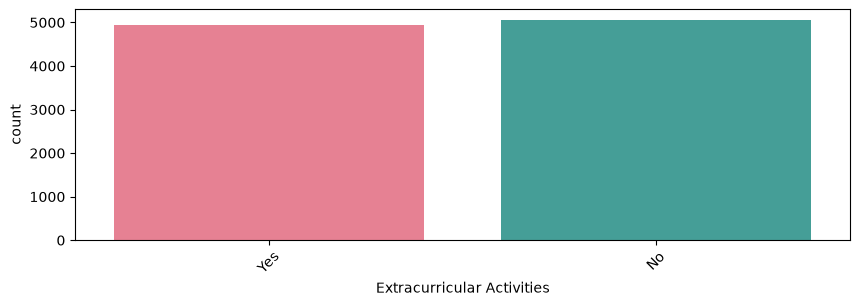

In [17]:
# visualiser les countplots
for col in cat_data.columns:
  countplot_func(col)

In [18]:
# sauvegarder les valeurs uniques de la variable catégorielle (avant l'encodage) en utilisant joblib
# dictionnaire {nom de la variable : liste de ses valeurs}, utilisé pour le Dropdown de l'application Streamlit
uniques = {}
for col in cat_data.columns:
  uniques[col] = np.unique(df[col]).tolist()
joblib.dump(uniques, 'uniques.joblib')
uniques

{'Extracurricular Activities': ['No', 'Yes']}

In [19]:
# décrire les variables quantitatives
quant_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Hours Studied,10000.0,4.9929,2.589309,1.0,3.0,5.0,7.0,9.0
Previous Scores,10000.0,69.4457,17.343152,40.0,54.0,69.0,85.0,99.0
Sleep Hours,10000.0,6.5306,1.695863,4.0,5.0,7.0,8.0,9.0
Sample Question Papers Practiced,10000.0,4.5833,2.867348,0.0,2.0,5.0,7.0,9.0
Performance Index,10000.0,55.2248,19.212558,10.0,40.0,55.0,71.0,100.0


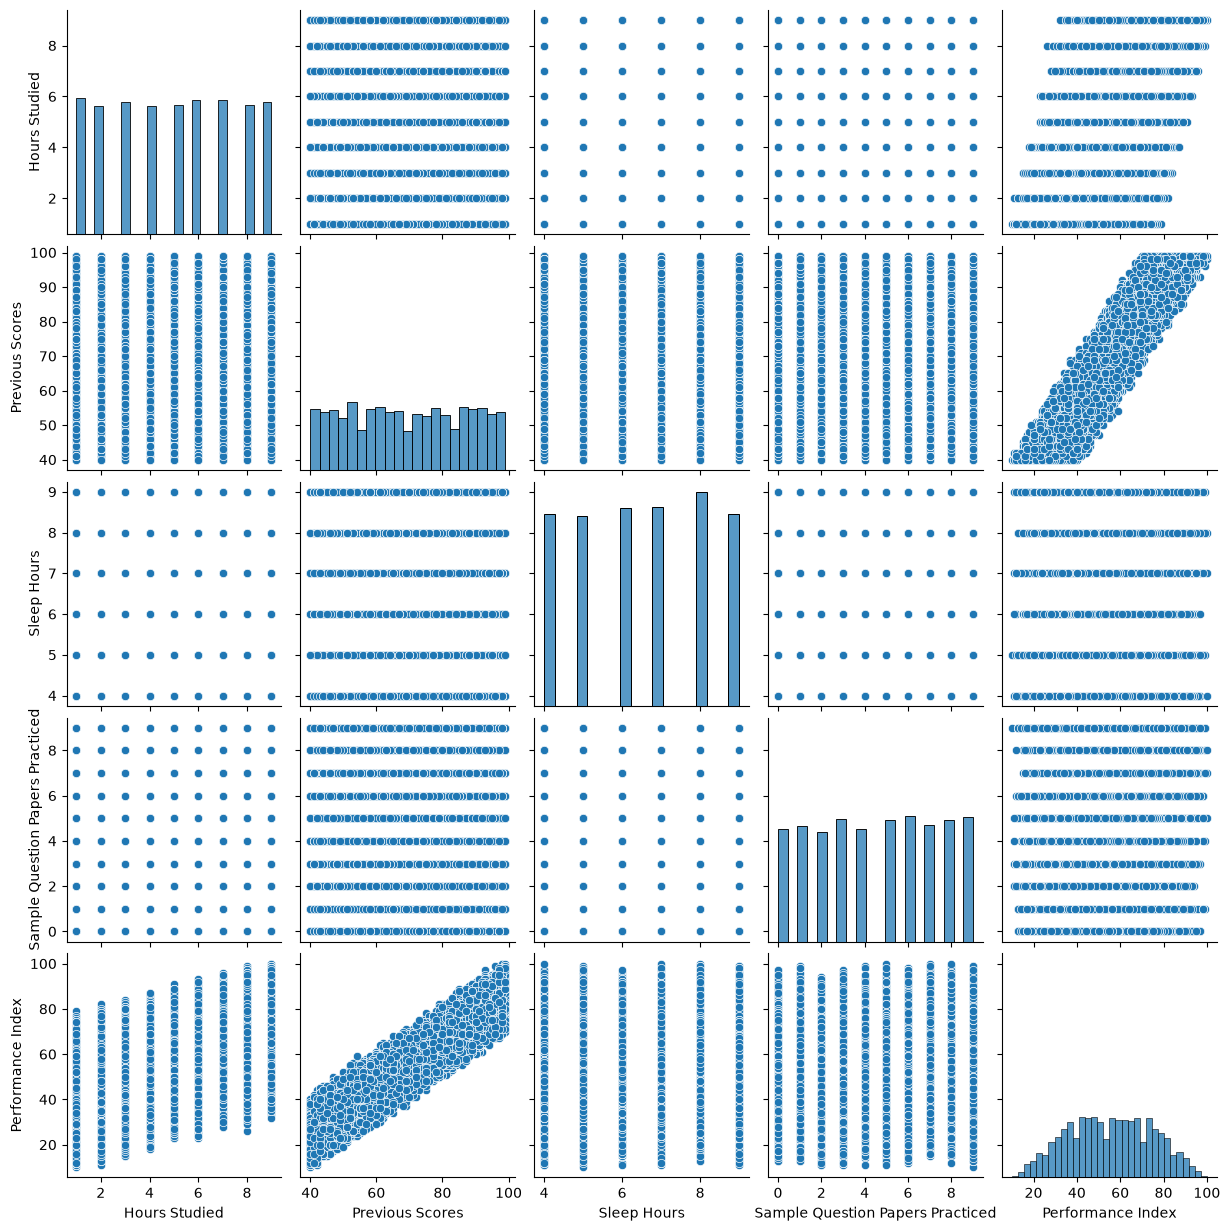

In [20]:
# pairplot des données
sns.pairplot(quant_data)
plt.show()

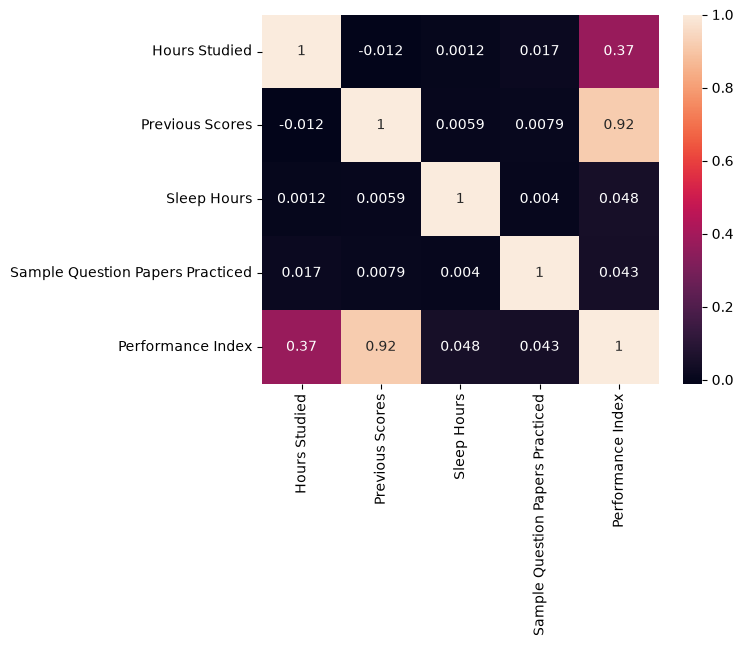

In [21]:
# matrice corrélation
sns.heatmap(quant_data.corr(), annot = True)
plt.show()

In [22]:
# fonction boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

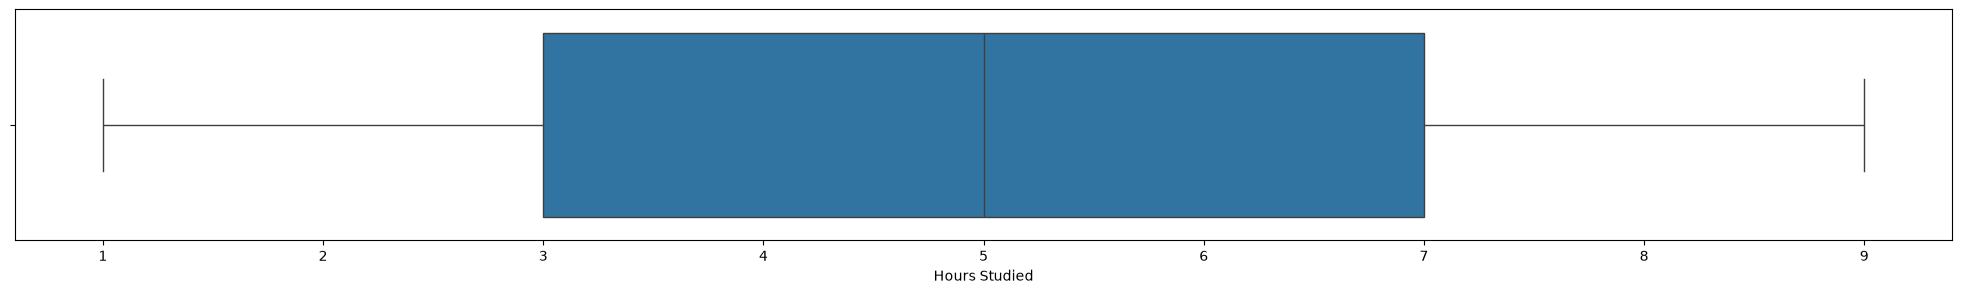

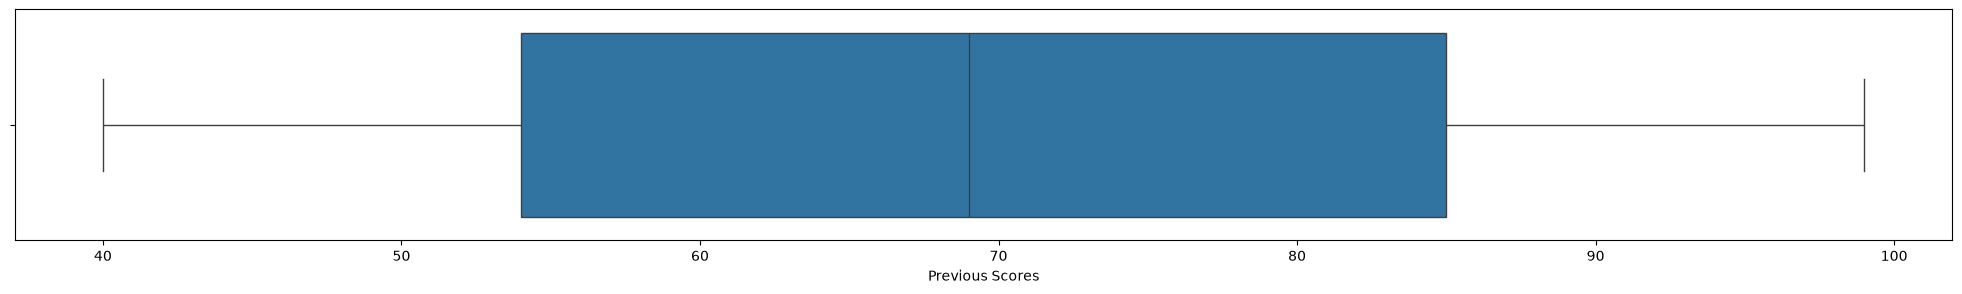

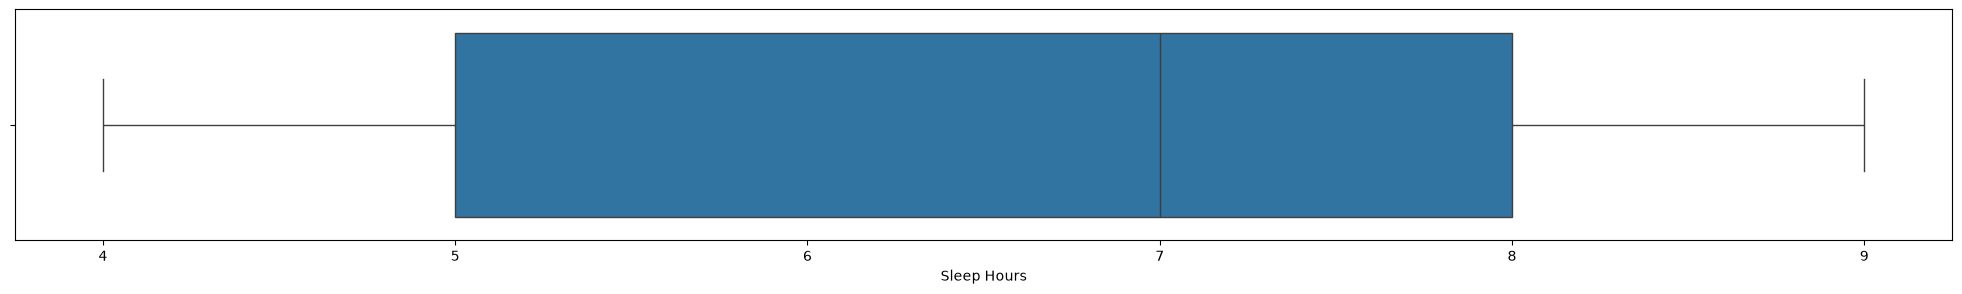

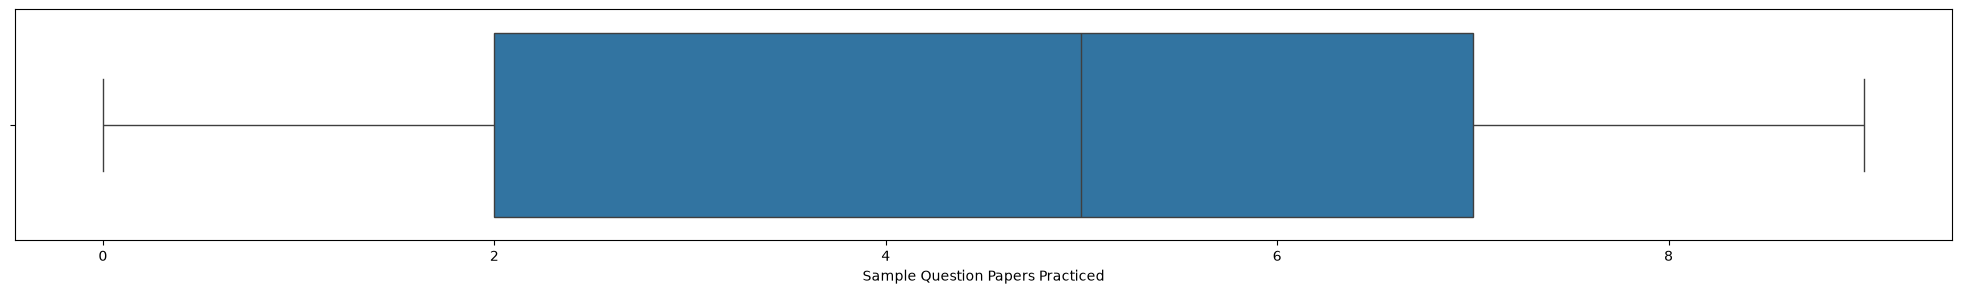

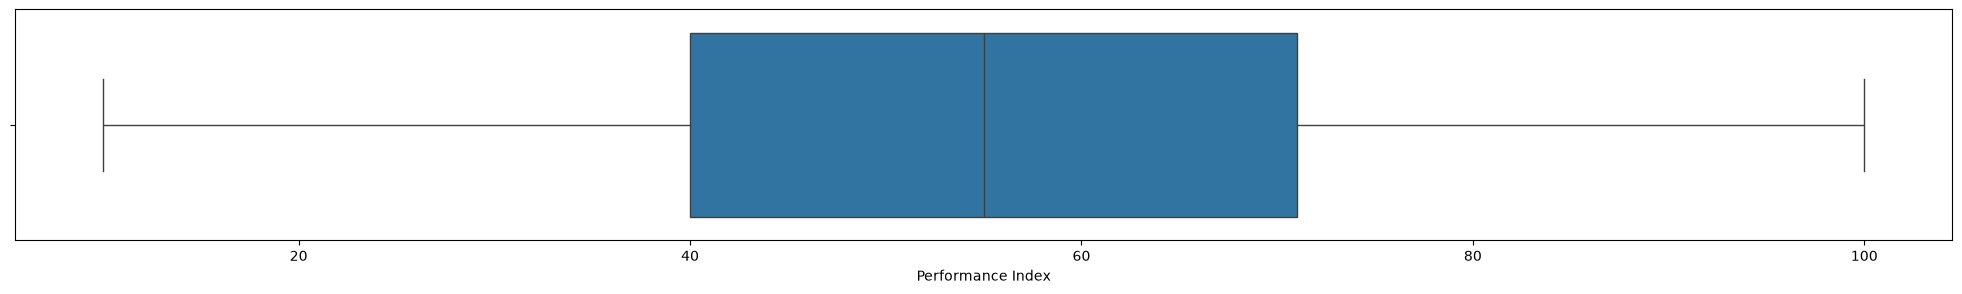

In [23]:
# boxplots des toutes les variables quantitatives
for col in quant_data.columns:
    boxplot_func(col)

## Préparation des données

In [24]:
# Encoder la variable catégorielle 'Extracurricular Activities'
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
encoder.fit(df['Extracurricular Activities'])
df['Extracurricular Activities'] = encoder.transform(df['Extracurricular Activities'])
# télécharger l'encodeur
joblib.dump(encoder, 'ExtracurricularActivities_encoder.joblib')
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


In [25]:
# Fractionner les données
x = df.drop('Performance Index', axis = 1).values
y = df['Performance Index'].values
x[:5], y[:5]

(array([[ 7, 99,  1,  9,  1],
        [ 4, 82,  0,  4,  2],
        [ 8, 51,  1,  7,  2],
        [ 5, 52,  1,  5,  2],
        [ 7, 75,  0,  8,  5]]),
 array([91., 65., 45., 36., 66.]))

In [26]:
# Normaliser les données
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
scaler.fit(x)
x = scaler.transform(x)
# télécharger le scaler
joblib.dump(scaler, 'scaler.joblib')
x[:5]

array([[ 0.5       ,  0.96774194,  1.        ,  0.66666667, -0.8       ],
       [-0.25      ,  0.41935484,  0.        , -1.        , -0.6       ],
       [ 0.75      , -0.58064516,  1.        ,  0.        , -0.6       ],
       [ 0.        , -0.5483871 ,  1.        , -0.66666667, -0.6       ],
       [ 0.5       ,  0.19354839,  0.        ,  0.33333333,  0.        ]])

In [27]:
# Splitter les données : 80% train, 10% validation, 10% test
from sklearn.model_selection import train_test_split
x_train, x_vt ,y_train, y_vt = train_test_split(x, y, test_size = 0.2, random_state = 42)
x_val, x_test, y_val, y_test = train_test_split(x_vt, y_vt, test_size = 0.5, random_state = 42)

In [28]:
# dimension des données train
x_train.shape, y_train.shape

((8000, 5), (8000,))

## Modélisation

### Recherche des hyperparamètres optimaux avec Keras Tuner

Hyperparamètres recherchés : le nombre de neurones des trois couches cachées (de 32 à 512, pas de 32) et la fonction d'activation de chacune (`relu` ou `tanh`).

Choix faits (corrections par rapport à la version du cours) :
- la perte est `mean_absolute_error` et la métrique `r2_score`, **identiques dans le tuner et dans le modèle final** ;
- l'objectif du tuner est `val_loss`, une mesure réellement suivie pendant l'entraînement (`mean_squared_error` n'était pas une métrique déclarée dans `compile`) ;
- l'activation de la couche de sortie est `relu` (comme dans le cours) : le `Performance Index` est une valeur positive (entre 10 et 100), `relu` empêche donc le modèle de prédire une valeur négative.

In [29]:
# Installer keras tuner (et tensorboard, nécessaire à keras tuner)
%pip install keras-tuner tensorboard

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
# importer le package keras_tuner
import keras_tuner as kt

# fonction build_model
def build_model(hp):
  model = Sequential() # initialiser l'architecture DNN

  # Choisir le nombre de neurones optimal pour les couches cachées entre 32 et 512
  # avec un pas de 32
  hp_units1 = hp.Int('units1', min_value=32, max_value=512, step=32)
  hp_units2 = hp.Int('units2', min_value=32, max_value=512, step=32)
  hp_units3 = hp.Int('units3', min_value=32, max_value=512, step=32)
  # Choisir la fonction d'activation optimale pour les couches cachées
  hp_activation1 = hp.Choice('activation_func1', values = ['relu', 'tanh'])
  hp_activation2 = hp.Choice('activation_func2', values = ['relu', 'tanh'])
  hp_activation3 = hp.Choice('activation_func3', values = ['relu', 'tanh'])
  # Ajouter les couches cachées
  model.add(Dense(units=hp_units1, activation=hp_activation1, input_shape = (x_train.shape[1], )))
  model.add(Dense(units=hp_units2, activation=hp_activation2))
  model.add(Dense(units=hp_units3, activation=hp_activation3))
  # couche de sortie : 1 neurone et relu (l'indice de performance est positif)
  model.add(Dense(1, activation='relu'))

  # compiler le modèle (même perte et même métrique que le modèle final)
  model.compile(optimizer='adam',
                loss='mean_absolute_error',
                metrics=['r2_score'])

  return model

In [31]:
# Initialiser le tuner
tuner = kt.Hyperband(build_model,
                     objective='val_loss',      # on minimise la perte sur les données de validation
                     max_epochs=20,
                     directory='tuner_dir',
                     project_name='dnn_student',
                     overwrite=True)

# lancer la recherche avec le tuner
tuner.search(x_train, y_train, validation_data = (x_val, y_val), epochs = 20)

Trial 30 Complete [00h 00m 33s]
val_loss: 1.6874245405197144

Best val_loss So Far: 1.656552791595459
Total elapsed time: 00h 11m 41s


In [32]:
# Afficher les paramètres optimaux
best_hps = tuner.get_best_hyperparameters()[0]
for h_param in [f"units{i}" for i in range(1,4)] + [f'activation_func{i}' for i in range(1,4)]:
  print(h_param, best_hps.get(h_param))

units1 512
units2 128
units3 416
activation_func1 tanh
activation_func2 relu
activation_func3 relu


### Modèle final avec les hyperparamètres optimaux

In [33]:
# Définir le modèle DNN avec les hyperparamètres optimaux trouvés par le tuner
from keras.callbacks import EarlyStopping
model = Sequential([
       # couche d'entrée avec units1 neurones et activation_func1 comme fonction d'activation
       Dense(units = best_hps.get('units1'), activation = best_hps.get('activation_func1'), input_shape = (x_train.shape[1], )),
       # première couche cachée avec units2 neurones et activation_func2 comme fonction d'activation
       Dense(units = best_hps.get('units2'), activation = best_hps.get('activation_func2')),
       # deuxième couche cachée avec units3 neurones et activation_func3 comme fonction d'activation
       Dense(units = best_hps.get('units3'), activation = best_hps.get('activation_func3')),
       # couche de sortie avec 1 neurone et relu comme fonction d'activation
       Dense(units = 1, activation = 'relu')
     ])

# compiler le modèle
model.compile(optimizer='adam',
                loss='mean_absolute_error',
                metrics=['r2_score'])

# Définir le early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3)
# Entrainer le modèle
history = model.fit(x_train, y_train, validation_data = (x_val, y_val), epochs = 30, callbacks = early_stopping)

Epoch 1/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 9.2516 - r2_score: 0.0367 - val_loss: 1.8464 - val_r2_score: 0.9862
Epoch 2/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 2.0082 - r2_score: 0.9829 - val_loss: 1.6695 - val_r2_score: 0.9886
Epoch 3/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 1.8559 - r2_score: 0.9852 - val_loss: 1.8527 - val_r2_score: 0.9862
Epoch 4/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.8671 - r2_score: 0.9850 - val_loss: 2.0203 - val_r2_score: 0.9834
Epoch 5/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 1.8596 - r2_score: 0.9852 - val_loss: 1.6832 - val_r2_score: 0.9882


In [34]:
# Afficher
history.history

{'loss': [9.251643180847168,
  2.0082058906555176,
  1.8559253215789795,
  1.8670856952667236,
  1.8596450090408325],
 'r2_score': [0.03666716814041138,
  0.9828510880470276,
  0.9851726293563843,
  0.9850121736526489,
  0.985247015953064],
 'val_loss': [1.8463971614837646,
  1.6695139408111572,
  1.8526630401611328,
  2.0203113555908203,
  1.6831541061401367],
 'val_r2_score': [0.9861936569213867,
  0.9886209964752197,
  0.9862023591995239,
  0.9834486246109009,
  0.9882413148880005]}

In [35]:
# télécharger le modèle
model.save('DNN_student_model.h5')
model.save('DNN_student_model.keras')

### Evaluation du modèle

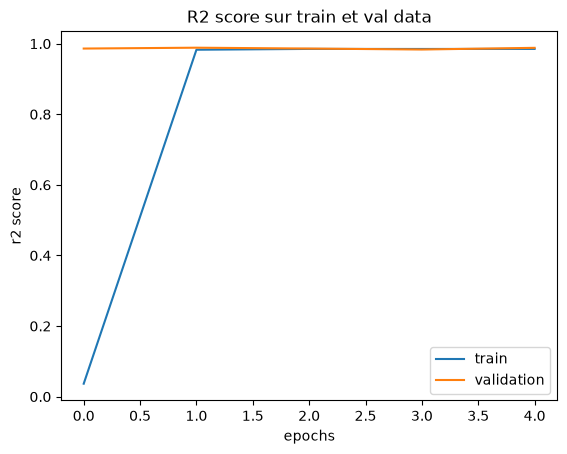

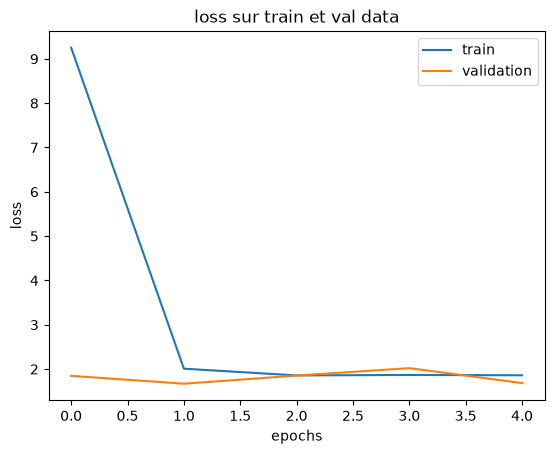

In [36]:
# plotter le r2 score sur les données d'entrainement et de validation suivant les différents epochs
plt.plot(history.history['r2_score'])
plt.plot(history.history['val_r2_score'])
plt.title('R2 score sur train et val data')
plt.xlabel('epochs')
plt.ylabel('r2 score')
plt.legend(['train', 'validation'], loc = 'lower right')
plt.show()
# plotter les erreurs sur les données d'entrainement et sur les données de validation suivant les différents epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('loss sur train et val data')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend(['train', 'validation'], loc = 'upper right')
plt.show()

In [37]:
# Erreur et R2 score sur les données de validation
val_metrics = model.evaluate(x_val, y_val)
print(f"R2 Score : {val_metrics[1]} --------- Loss : {val_metrics[0]}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.6832 - r2_score: 0.9882
R2 Score : 0.9882413148880005 --------- Loss : 1.6831541061401367


In [38]:
# Erreur et R2 score sur les données d'entrainement
train_metrics = model.evaluate(x_train, y_train)
print(f"R2 Score : {train_metrics[1]} --------- Loss : {train_metrics[0]}")

250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.7202 - r2_score: 0.9873
R2 Score : 0.9872840642929077 --------- Loss : 1.7201687097549438


In [39]:
# Erreur et R2 score sur les données test
test_metrics = model.evaluate(x_test, y_test)
print(f"R2 Score : {test_metrics[1]} --------- Loss : {test_metrics[0]}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.7114 - r2_score: 0.9874
R2 Score : 0.9873563051223755 --------- Loss : 1.7113853693008423


#### Tester le modèle

In [40]:
# Tester le modèle avec quelques données test
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]
# prédictions
y_pred_10 = model.predict(x_test_10)
# afficher les prédictions
for i in range(10):
  print(f'Prédiction {str(i+1)} : {round(y_pred_10[i][0],0)} -- {round(y_test_10[i], 0)}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 487ms/step
Prédiction 1 : 73.0 -- 74.0
Prédiction 2 : 65.0 -- 63.0
Prédiction 3 : 46.0 -- 47.0
Prédiction 4 : 63.0 -- 63.0
Prédiction 5 : 36.0 -- 37.0
Prédiction 6 : 55.0 -- 54.0
Prédiction 7 : 45.0 -- 43.0
Prédiction 8 : 44.0 -- 44.0
Prédiction 9 : 35.0 -- 36.0
Prédiction 10 : 66.0 -- 63.0


### Préparation pour le déploiement avec Streamlit

On sauvegarde dans le dossier `Projet/TP2` les fichiers nécessaires à l'application : le modèle `.h5`, le `scaler`, l'encodeur de `Extracurricular Activities` et les valeurs uniques. La fonction de prédiction utilise **le même prétraitement que l'entraînement** (encodage, puis scaler) ; elle sera reprise dans `app.py`.

In [41]:
# Copier le modèle, le scaler, l'encodeur et les valeurs uniques dans le dossier du projet (utilisé par l'application Streamlit)
import shutil
dossier = 'Projet/TP2'
os.makedirs(dossier, exist_ok = True)
for f in ['DNN_student_model.h5', 'DNN_student_model.keras', 'scaler.joblib', 'ExtracurricularActivities_encoder.joblib', 'uniques.joblib']:
  shutil.copy(f, dossier)
os.listdir(dossier)

['DNN_student_model.h5',
 'DNN_student_model.keras',
 'ExtracurricularActivities_encoder.joblib',
 'scaler.joblib',
 'uniques.joblib']

In [42]:
# Fonction de prédiction (même prétraitement que dans l'application Streamlit)
from keras.models import load_model
model = load_model('DNN_student_model.h5')
scaler = joblib.load('scaler.joblib')
encoder = joblib.load('ExtracurricularActivities_encoder.joblib')

def prediction_func(hours_studied, previous_scores, extracurricular, sleep_hours, papers_practiced):
  # encoder la variable catégorielle
  extracurricular = encoder.transform([extracurricular])[0]
  # vecteur des valeurs (même ordre que les colonnes du jeu de données)
  x_new = np.array([hours_studied, previous_scores, extracurricular, sleep_hours, papers_practiced]).reshape(1, -1)
  # normaliser les valeurs
  x_new = scaler.transform(x_new)
  # prédire l'indice de performance
  return float(model.predict(x_new, verbose = 0)[0][0])

In [43]:
# Tester la fonction de prédiction avec un étudiant
print('Indice de performance prédit :', round(prediction_func(7, 99, 'Yes', 9, 1), 1))

Indice de performance prédit : 92.6
